# Assignment 10: revised labels and the retrained classifier

This notebook does six things.

1. Compute Krippendorff's alpha on the Assignment 7 labels (the baseline agreement).
2. Compute the same alpha on the Module 10 form labels (the revised agreement).
3. Prepare the training labels. Where a Module 10 message is the same statement as an Assignment 9 message, the majority label replaces `expand_other`. Every other Assignment 9 label stays.
4. Retrain the Assignment 9 classifier. The model, the TF-IDF unigrams, the hyperparameters, and the ten 20/10 splits stay the same.
5. Score precision, recall, F1, specificity, one-vs-rest AUC, and the confusion matrix with the Assignment 9 definitions.
6. Compare the baseline and the retrained classifier on the same held-out messages.

Run this notebook from `Module_10_assignment` or from the repository root. It needs `pandas`, `numpy`, `scikit-learn`, and `matplotlib`.


## Agreement measure

Krippendorff's alpha is the agreement summary for both rounds. It is one coefficient for any number of raters, it still applies when a rating is missing, and the same formula accepts a nominal distance. Cohen's kappa is defined for two raters, so five annotators would have to be collapsed into pairs. Fleiss's kappa allows several raters, but the usual formula requires the same number of ratings on every item.

Nominal alpha uses the coincidence counts inside each message:

`alpha = 1 - (D_o / D_e)`

`D_o = (n - diagonal) / n` is the observed disagreement. The diagonal entry for a category is the sum, over messages, of `count * (count - 1) / (ratings_on_that_message - 1)`. `n` is the number of codes. `D_e = (n^2 - sum of squared category totals) / (n * (n - 1))` is the disagreement expected from those totals. `final_label` is not a rater.


In [1]:
%matplotlib inline
from pathlib import Path
import json
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, roc_auc_score
from sklearn.pipeline import Pipeline

# Same training setup as Assignment 9.
TRAIN_SIZE = 20
N_REPEATS = 10
RANDOM_SEED = 42
CLASS_NAMES = [
    "buyer",
    "seller",
    "renter",
    "media outreach",
    "realtor network",
    "other",
]
METRIC_NAMES = ["precision", "recall", "f1", "specificity", "auc"]

# Assignment 9 item id -> Module 10 item id. The next data cell checks the statement text.
MATCHED_ITEM_IDS = {
    "V1": "V2",
    "V3": "V5",
    "V6": "V12",
    "V7": "V21",
    "V8": "V24",
    "V9": "V13",
    "V11": "V4",
    "V16": "V15",
    "V17": "V23",
    "V20": "V18",
    "V21": "V8",
    "V22": "V9",
    "V23": "V7",
    "V27": "V19",
    "V28": "V3",
    "V30": "V1",
}


def repo_root():
    # The notebook is runnable from this folder or from the repository root.
    cwd = Path.cwd().resolve()
    for candidate in (cwd, cwd.parent):
        module_9 = candidate / "Module_9_assignment" / "labeled_visitor_intent.csv"
        module_7 = candidate / "Module_7_assignment" / "labeled_visitor_intent.csv"
        if module_9.exists() and module_7.exists():
            return candidate
    raise FileNotFoundError("Run this notebook from Module_10_assignment or the repository root.")


ROOT = repo_root()
MODULE_7 = ROOT / "Module_7_assignment" / "labeled_visitor_intent.csv"
MODULE_9 = ROOT / "Module_9_assignment" / "labeled_visitor_intent.csv"
MODULE_10 = ROOT / "Module_10_assignment" / "labeled_visitor_intent.csv"
OUTPUT_DIR = ROOT / "Module_10_assignment" / "outputs"


def normalize_label(raw_label):
    if raw_label is None or (isinstance(raw_label, float) and np.isnan(raw_label)):
        return ""
    text = str(raw_label).strip()
    if text == "" or text.lower() == "nan":
        return ""
    return " ".join(text.lower().split())


def nominal_alpha(frame, rater_columns):
    # Coincidence form of nominal Krippendorff alpha. A blank cell is a missing rating.
    category_totals = {}
    diagonal = {}
    pairable_values = 0
    for _, row in frame.iterrows():
        present = [normalize_label(row[column]) for column in rater_columns]
        present = [label for label in present if label]
        rater_count = len(present)
        if rater_count < 2:
            continue
        pairable_values += rater_count
        counts = {}
        for label in present:
            counts[label] = counts.get(label, 0) + 1
            category_totals[label] = category_totals.get(label, 0) + 1
        for label, count in counts.items():
            coincidence = count * (count - 1) / (rater_count - 1)
            diagonal[label] = diagonal.get(label, 0.0) + coincidence

    diagonal_sum = sum(diagonal.values())
    observed_disagreement = (pairable_values - diagonal_sum) / pairable_values
    squared_totals = sum(count * count for count in category_totals.values())
    expected_disagreement = (
        (pairable_values ** 2 - squared_totals)
        / (pairable_values * (pairable_values - 1))
    )
    alpha = 1 - observed_disagreement / expected_disagreement
    detail = pd.DataFrame({
        "category_total": pd.Series(category_totals),
        "diagonal_coincidence": pd.Series(diagonal),
    }).fillna(0).sort_values("category_total", ascending=False)
    detail.index.name = "category"
    return {
        "alpha": alpha,
        "pairable_values": pairable_values,
        "diagonal_sum": diagonal_sum,
        "observed_disagreement": observed_disagreement,
        "expected_disagreement": expected_disagreement,
        "detail": detail,
    }


def show_alpha(result, source_name, rater_count):
    print(f"Source: {source_name}")
    print(f"Raters: {rater_count}. Pairable codes: {result['pairable_values']}.")
    print(
        f"D_o = {result['observed_disagreement']:.6f}, "
        f"D_e = {result['expected_disagreement']:.6f}, "
        f"alpha = {result['alpha']:.3f} ({result['alpha']:.6f} unrounded)."
    )
    display(result["detail"])


print(f"Repository root: {ROOT}")
print(f"scikit-learn {sklearn.__version__}, numpy {np.__version__}")


E:\Python\Lib\site-packages\sklearn\__init__.py:82: UserWarning: A NumPy version >=1.22.4 and <2.3.0 is required for this version of SciPy (detected version 2.4.4)
  import scipy.linalg  # noqa


Repository root: E:\Human-in-the-loop-AI
scikit-learn 1.5.0, numpy 2.4.4


## Baseline IAA

The baseline matrix is the five annotator columns in `Module_7_assignment/labeled_visitor_intent.csv`. Those labels use four categories: buyer, seller, renter, and other. `final_label` is left out. This is the agreement before the Module 10 instructions and form.


In [2]:
baseline_labels = pd.read_csv(MODULE_7)
baseline_raters = [f"annotator_{index}" for index in range(1, 6)]
baseline_agreement = nominal_alpha(baseline_labels, baseline_raters)
show_alpha(baseline_agreement, MODULE_7.relative_to(ROOT), len(baseline_raters))
print(
    "Alpha is above chance. Krippendorff treats 0.800 as reliable and 0.667 as the "
    "floor for tentative conclusions, so 0.517 is usable as a baseline and is not reliable agreement."
)


Source: Module_7_assignment\labeled_visitor_intent.csv
Raters: 5. Pairable codes: 150.
D_o = 0.286667, D_e = 0.593468, alpha = 0.517 (0.516963 unrounded).


,category_total,diagonal_coincidence
category,,
buyer,87,74.0
other,35,18.5
renter,19,9.0
seller,9,5.5


Alpha is above chance. Krippendorff treats 0.800 as reliable and 0.667 as the floor for tentative conclusions, so 0.517 is usable as a baseline and is not reliable agreement.


## Revised IAA

The revised matrix is the four annotator columns in `Module_10_assignment/labeled_visitor_intent.csv`. The form uses six categories. The two rounds do not share raters, and only some of the messages are the same statements, so the two alphas are the before and after summaries of each labeling round. They are not a paired re-rating of one fixed set.


In [3]:
revised_form = pd.read_csv(MODULE_10)
revised_raters = [f"annotator_{index}" for index in range(1, 5)]
revised_agreement = nominal_alpha(revised_form, revised_raters)
show_alpha(revised_agreement, MODULE_10.relative_to(ROOT), len(revised_raters))
alpha_change = revised_agreement["alpha"] - baseline_agreement["alpha"]
print(
    f"Revised alpha is {revised_agreement['alpha']:.3f}, "
    f"compared with baseline alpha {baseline_agreement['alpha']:.3f} "
    f"(difference {alpha_change:+.3f})."
)
print(
    "The revised round has fewer raters and more categories. "
    "A higher alpha on that round is a small gain in the new labeling, "
    "and it still sits below the 0.667 tentative line."
)


Source: Module_10_assignment\labeled_visitor_intent.csv
Raters: 4. Pairable codes: 120.
D_o = 0.361111, D_e = 0.795658, alpha = 0.546 (0.546148 unrounded).


,category_total,diagonal_coincidence
category,,
buyer,39,29.333333
other,25,12.666667
realtor network,19,10.000000
renter,19,16.666667
media outreach,11,3.333333
seller,7,4.666667


Revised alpha is 0.546, compared with baseline alpha 0.517 (difference +0.029).
The revised round has fewer raters and more categories. A higher alpha on that round is a small gain in the new labeling, and it still sits below the 0.667 tentative line.


## Data preparation

Assignment 9 trained on `expand_other` for 30 messages. The Module 10 form is another 30 messages, and the item ids do not line up. A message is revised only when the statement matches. The majority label then replaces `expand_other` for that Assignment 9 id. Messages that were not on the form keep `expand_other`. Form messages that were not in Assignment 9 are not added, because adding them would change who is in the training and test sets.

A blank majority would also keep the Assignment 9 label. The two adjudicated ties in the form are messages that are not in the Assignment 9 file, so they stay out of this training set.

The visitor text is what the classifier reads. Only the label changes.


In [4]:
def content_tokens(text):
    lowered = str(text).lower()
    lowered = re.sub(r"\([^)]*\)", " ", lowered)
    lowered = re.sub(r"\[[^\]]*\]", " ", lowered)
    lowered = re.sub(r"x{2,}", " ", lowered)
    lowered = re.sub(r"[^a-z0-9]+", " ", lowered)
    return [token for token in lowered.split() if len(token) > 1]


def token_overlap(left_text, right_text):
    left_tokens = set(content_tokens(left_text))
    right_tokens = set(content_tokens(right_text))
    if not left_tokens and not right_tokens:
        return 1.0
    if not left_tokens or not right_tokens:
        return 0.0
    return len(left_tokens & right_tokens) / len(left_tokens | right_tokens)


def build_label_table(original, revised_source):
    revised_by_id = revised_source.set_index("item_id")
    rows = []
    revised_labels = []
    for _, original_row in original.iterrows():
        item_id = str(original_row["item_id"])
        original_label = normalize_label(original_row["expand_other"])
        module_10_id = MATCHED_ITEM_IDS.get(item_id)
        if module_10_id is None:
            rows.append({
                "item_id": item_id,
                "module_10_item_id": "",
                "original_label": original_label,
                "revised_label": original_label,
                "label_changed": False,
                "votes": "",
                "note": "Not on the Module 10 form. expand_other retained.",
            })
            revised_labels.append(original_label)
            continue

        revised_row = revised_by_id.loc[module_10_id]
        overlap = token_overlap(original_row["visitor_statement"], revised_row["visitor_statement"])
        if overlap < 0.9:
            raise ValueError(f"{item_id} does not match Module 10 {module_10_id} (overlap {overlap:.3f}).")
        votes = [
            normalize_label(revised_row[column])
            for column in ("annotator_1", "annotator_2", "annotator_3", "annotator_4")
        ]
        majority_label = normalize_label(revised_row["final_label"])
        if majority_label == "":
            applied_label = original_label
            changed = False
            note = "No majority label. expand_other retained."
        else:
            applied_label = majority_label
            changed = applied_label != original_label
            note = "Majority label replaced expand_other." if changed else "Majority label matches expand_other."
        rows.append({
            "item_id": item_id,
            "module_10_item_id": module_10_id,
            "original_label": original_label,
            "revised_label": applied_label,
            "label_changed": changed,
            "votes": " | ".join(votes),
            "note": note,
        })
        revised_labels.append(applied_label)
    return pd.DataFrame(rows), np.asarray(revised_labels)


original = pd.read_csv(MODULE_9)
label_table, revised_labels = build_label_table(original, revised_form)
original_labels = original["expand_other"].map(normalize_label).to_numpy()
unknown_labels = sorted((set(original_labels) | set(revised_labels)) - set(CLASS_NAMES))
if unknown_labels:
    raise ValueError("Unexpected labels: " + ", ".join(unknown_labels))

statements = original["visitor_statement"].astype(str).to_numpy()
item_ids = original["item_id"].astype(str).to_numpy()

changed_labels = label_table.loc[label_table["label_changed"]].copy()
changed_labels.insert(1, "visitor_statement", changed_labels["item_id"].map(
    original.set_index("item_id")["visitor_statement"]
))
print(f"Matched messages: {label_table['module_10_item_id'].astype(bool).sum()} of {len(original)}.")
print(f"Labels changed: {len(changed_labels)}. Labels retained: {(~label_table['label_changed']).sum()}.")
print("Changed labels:")
display(changed_labels)

count_table = pd.DataFrame({
    "assignment_9": pd.Series(original_labels).value_counts(),
    "revised": pd.Series(revised_labels).value_counts(),
}).reindex(CLASS_NAMES).fillna(0).astype(int)
count_table.index.name = "class_name"
print("Class counts on the same 30 messages:")
display(count_table)

matched_form_ids = set(MATCHED_ITEM_IDS.values())
excluded_form = revised_form.loc[~revised_form["item_id"].isin(matched_form_ids), ["item_id", "final_label", "adjudicated"]]
print(f"Form messages left out of training, so the Assignment 9 splits stay intact: {len(excluded_form)}.")
display(excluded_form)


Matched messages: 16 of 30.
Labels changed: 3. Labels retained: 27.
Changed labels:


,item_id,visitor_statement,module_10_item_id,original_label,revised_label,label_changed,votes,note
15,V16,Hello. I have watched several of xxx(name)'s v...,V15,renter,buyer,True,buyer | realtor network | buyer | renter,Majority label replaced expand_other.
21,V22,"Hi, we're looking to move to the Celebration/W...",V9,other,buyer,True,buyer | buyer | other | buyer,Majority label replaced expand_other.
26,V27,How does the problem of blue green algae affec...,V19,media outreach,other,True,other | media outreach | buyer | other,Majority label replaced expand_other.


Class counts on the same 30 messages:


,assignment_9,revised
class_name,,
buyer,19,21
seller,1,1
renter,3,2
media outreach,2,1
realtor network,1,1
other,4,4


Form messages left out of training, so the Assignment 9 splits stay intact: 14.


,item_id,final_label,adjudicated
5,V6,Other,No
9,V10,Renter,No
10,V11,Seller,Yes
13,V14,Realtor Network,No
15,V16,Media Outreach,No
16,V17,Renter,No
19,V20,Other,No
21,V22,Media Outreach,No
24,V25,Other,No
25,V26,Buyer,No


## Retraining

The classifier is the Assignment 9 pipeline: word-unigram TF-IDF (`lowercase`, `ngram_range=(1, 1)`, `min_df=1`) and L2 logistic regression (`C=1.0`, `class_weight="balanced"`, `solver="lbfgs"`, `max_iter=1000`, `random_state=42`). Each repeat refits the vectorizer on that repeat's 20 training rows. Repeat k uses `RandomState(42 + k - 1)` and takes the first 20 positions of the permutation as training rows. The other 10 are the test.

Assignment 9 used one label array for training and scoring. This notebook keeps those arrays separate so the test key can stay on `expand_other` while the model trains on the revised labels. Test rows are never fit. When both arrays are `expand_other`, the run is the Assignment 9 baseline.

A class that is missing from a training split has no coefficient. Its probability stays 0, which makes its one-vs-rest AUC 0.5 whenever that class appears in the test set. Precision is N/A when the model never predicts the class. Recall is N/A when the class is absent from the test set. F1 is N/A when either of those is N/A, and F1 is 0 when precision and recall are both 0. Specificity is N/A when the negative class is absent. Macro scores are the unweighted mean of the classes whose metric is defined on that repeat. A class with N/A is left out of the mean.


In [5]:
def make_pipeline():
    return Pipeline(
        steps=[
            (
                "tfidf",
                TfidfVectorizer(
                    lowercase=True,
                    ngram_range=(1, 1),
                    min_df=1,
                ),
            ),
            (
                "classifier",
                LogisticRegression(
                    C=1.0,
                    class_weight="balanced",
                    solver="lbfgs",
                    max_iter=1000,
                    random_state=RANDOM_SEED,
                ),
            ),
        ]
    )


def train_test_positions(row_count, train_size, split_seed):
    generator = np.random.RandomState(split_seed)
    positions = generator.permutation(row_count)
    return positions[:train_size], positions[train_size:]


def class_probabilities(pipeline, text_rows, class_names):
    # Classes absent from the training rows have no coefficient. Their score stays 0.
    raw_probabilities = pipeline.predict_proba(text_rows)
    trained_names = list(pipeline.named_steps["classifier"].classes_)
    aligned = np.zeros((len(text_rows), len(class_names)), dtype=float)
    for column_index, class_name in enumerate(trained_names):
        aligned[:, class_names.index(class_name)] = raw_probabilities[:, column_index]
    return aligned


def safe_divide(numerator, denominator):
    if denominator == 0:
        return np.nan
    return numerator / denominator


def f1_from_precision_recall(precision, recall):
    if np.isnan(precision) or np.isnan(recall):
        return np.nan
    if precision + recall == 0:
        return 0.0
    return 2 * precision * recall / (precision + recall)


def one_vs_rest_counts(true_labels, predicted_labels, positive_name):
    true_positive = 0
    false_positive = 0
    true_negative = 0
    false_negative = 0
    for true_label, predicted_label in zip(true_labels, predicted_labels):
        actual_positive = true_label == positive_name
        predicted_positive = predicted_label == positive_name
        if actual_positive and predicted_positive:
            true_positive += 1
        elif actual_positive and not predicted_positive:
            false_negative += 1
        elif (not actual_positive) and predicted_positive:
            false_positive += 1
        else:
            true_negative += 1
    return true_positive, false_positive, true_negative, false_negative


def one_vs_rest_auc(true_labels, positive_scores, positive_name):
    binary_truth = np.asarray([1 if label == positive_name else 0 for label in true_labels], dtype=int)
    positive_count = int(binary_truth.sum())
    if positive_count == 0 or positive_count == len(binary_truth):
        return np.nan
    return float(roc_auc_score(binary_truth, positive_scores))


def macro_average(values):
    numeric_values = np.asarray(values, dtype=float)
    defined_values = numeric_values[~np.isnan(numeric_values)]
    if defined_values.size == 0:
        return np.nan
    return float(defined_values.mean())


def join_names(names):
    if len(names) == 0:
        return "(none)"
    return ", ".join(names)


def score_repeat(repeat_number, split_seed, text_rows, train_labels, reference_labels, ids):
    train_positions, test_positions = train_test_positions(len(text_rows), TRAIN_SIZE, split_seed)
    pipeline = make_pipeline()
    pipeline.fit(text_rows[train_positions], train_labels[train_positions])

    actual_labels = reference_labels[test_positions]
    predicted_labels = pipeline.predict(text_rows[test_positions])
    probabilities = class_probabilities(pipeline, text_rows[test_positions], CLASS_NAMES)
    trained_classes = set(pipeline.named_steps["classifier"].classes_)

    class_rows = []
    for class_index, class_name in enumerate(CLASS_NAMES):
        true_positive, false_positive, true_negative, false_negative = one_vs_rest_counts(
            actual_labels, predicted_labels, class_name
        )
        precision = safe_divide(true_positive, true_positive + false_positive)
        recall = safe_divide(true_positive, true_positive + false_negative)
        class_rows.append({
            "repeat": repeat_number,
            "split_seed": split_seed,
            "class_name": class_name,
            "precision": precision,
            "recall": recall,
            "f1": f1_from_precision_recall(precision, recall),
            "specificity": safe_divide(true_negative, true_negative + false_positive),
            "auc": one_vs_rest_auc(actual_labels, probabilities[:, class_index], class_name),
            "test_support": int(np.sum(actual_labels == class_name)),
            "train_support": int(np.sum(train_labels[train_positions] == class_name)),
            "true_positive": true_positive,
            "false_positive": false_positive,
            "true_negative": true_negative,
            "false_negative": false_negative,
        })

    prediction_rows = []
    for row_index, position in enumerate(test_positions):
        prediction_rows.append({
            "repeat": repeat_number,
            "split_seed": split_seed,
            "item_id": ids[position],
            "actual_label": actual_labels[row_index],
            "predicted_label": predicted_labels[row_index],
            "correct": bool(actual_labels[row_index] == predicted_labels[row_index]),
        })

    confusion_counts = confusion_matrix(actual_labels, predicted_labels, labels=CLASS_NAMES)
    summary = {
        "repeat": repeat_number,
        "split_seed": split_seed,
        "accuracy": float(np.mean(actual_labels == predicted_labels)),
        "macro_precision": macro_average([row["precision"] for row in class_rows]),
        "macro_recall": macro_average([row["recall"] for row in class_rows]),
        "macro_f1": macro_average([row["f1"] for row in class_rows]),
        "macro_specificity": macro_average([row["specificity"] for row in class_rows]),
        "macro_auc": macro_average([row["auc"] for row in class_rows]),
        "f1_classes_counted": int(np.sum(~np.isnan([row["f1"] for row in class_rows]))),
        "classes_missing_from_train": join_names(
            [class_name for class_name in CLASS_NAMES if class_name not in trained_classes]
        ),
        "classes_missing_from_test": join_names(
            [row["class_name"] for row in class_rows if row["test_support"] == 0]
        ),
    }
    return class_rows, summary, prediction_rows, confusion_counts


def run_experiment(text_rows, train_labels, reference_labels, ids):
    class_rows = []
    repeat_rows = []
    prediction_rows = []
    summed_confusion = np.zeros((len(CLASS_NAMES), len(CLASS_NAMES)), dtype=int)
    for repeat_index in range(N_REPEATS):
        repeat_class_rows, summary, repeat_predictions, confusion_counts = score_repeat(
            repeat_index + 1,
            RANDOM_SEED + repeat_index,
            text_rows,
            train_labels,
            reference_labels,
            ids,
        )
        class_rows.extend(repeat_class_rows)
        repeat_rows.append(summary)
        prediction_rows.extend(repeat_predictions)
        summed_confusion = summed_confusion + confusion_counts

    class_metrics = pd.DataFrame(class_rows)
    summary_rows = []
    for class_name in CLASS_NAMES:
        class_frame = class_metrics.loc[class_metrics["class_name"] == class_name]
        summary_row = {
            "class_name": class_name,
            "test_support_total": int(class_frame["test_support"].sum()),
            "train_support_total": int(class_frame["train_support"].sum()),
        }
        for metric_name in METRIC_NAMES:
            defined_values = class_frame[metric_name].dropna()
            summary_row[metric_name + "_mean"] = macro_average(class_frame[metric_name].to_numpy())
            if len(defined_values) < 2:
                summary_row[metric_name + "_std"] = np.nan
            else:
                summary_row[metric_name + "_std"] = float(defined_values.std(ddof=1))
            summary_row[metric_name + "_defined_runs"] = int(defined_values.shape[0])
        summary_rows.append(summary_row)
    return {
        "class_summary": pd.DataFrame(summary_rows),
        "repeat_summary": pd.DataFrame(repeat_rows),
        "predictions": pd.DataFrame(prediction_rows),
        "confusion": summed_confusion,
    }


saved_splits = json.loads((ROOT / "Module_9_assignment" / "outputs" / "run_settings.json").read_text(encoding="utf-8"))
for repeat_index, saved_split in enumerate(saved_splits["splits"]):
    train_positions, test_positions = train_test_positions(len(item_ids), TRAIN_SIZE, RANDOM_SEED + repeat_index)
    train_ids = [str(item_ids[position]) for position in train_positions]
    test_ids = [str(item_ids[position]) for position in test_positions]
    if train_ids != saved_split["train_item_ids"] or test_ids != saved_split["test_item_ids"]:
        raise ValueError(f"Repeat {repeat_index + 1} does not match the Assignment 9 split.")
print("All 10 training and test id lists match Assignment 9.")

# Four runs separate retraining from a change in the test labels.
experiments = {
    "Baseline, original labels": run_experiment(statements, original_labels, original_labels, item_ids),
    "Revised model, original labels": run_experiment(statements, revised_labels, original_labels, item_ids),
    "Baseline model, revised labels": run_experiment(statements, original_labels, revised_labels, item_ids),
    "Revised model, revised labels": run_experiment(statements, revised_labels, revised_labels, item_ids),
}
print(f"Finished {len(experiments)} experiments, each with {N_REPEATS} repeats.")


All 10 training and test id lists match Assignment 9.


Finished 4 experiments, each with 10 repeats.


## Performance evaluation

The first table is the retrained classifier scored on the original `expand_other` test labels. That holds the test key fixed, so the difference from Assignment 9 is the training labels.

The second table scores the same retrained classifier on the revised test labels. Use it together with the comparison section. The jump between the two tables mixes the new training labels with a new answer key.

Means skip repeats where the metric is N/A. `defined_runs` counts how many of the 10 test sets produced a number. The macro row is the mean of the 10 repeat-level macro scores, which is the Assignment 9 summary. The confusion matrix pools the 10 test sets, so it contains 100 predictions and some messages appear more than once.


In [6]:
def format_metric(value):
    if pd.isna(value):
        return "N/A"
    return f"{value:.3f}"


def performance_table(experiment):
    class_summary = experiment["class_summary"]
    rows = []
    for _, summary_row in class_summary.iterrows():
        rows.append({
            "class_name": summary_row["class_name"],
            "precision": format_metric(summary_row["precision_mean"]),
            "recall": format_metric(summary_row["recall_mean"]),
            "f1": format_metric(summary_row["f1_mean"]),
            "specificity": format_metric(summary_row["specificity_mean"]),
            "auc": format_metric(summary_row["auc_mean"]),
            "precision_defined_runs": int(summary_row["precision_defined_runs"]),
            "recall_defined_runs": int(summary_row["recall_defined_runs"]),
            "auc_defined_runs": int(summary_row["auc_defined_runs"]),
        })
    repeat_summary = experiment["repeat_summary"]
    rows.append({
        "class_name": "macro mean of repeats",
        "precision": format_metric(repeat_summary["macro_precision"].mean()),
        "recall": format_metric(repeat_summary["macro_recall"].mean()),
        "f1": format_metric(repeat_summary["macro_f1"].mean()),
        "specificity": format_metric(repeat_summary["macro_specificity"].mean()),
        "auc": format_metric(repeat_summary["macro_auc"].mean()),
        "precision_defined_runs": "",
        "recall_defined_runs": "",
        "auc_defined_runs": "",
    })
    return pd.DataFrame(rows)


def confusion_frame(experiment):
    frame = pd.DataFrame(experiment["confusion"], index=CLASS_NAMES, columns=CLASS_NAMES)
    frame.index.name = "actual_label"
    return frame


print(
    "Retrained classifier on the original test labels. "
    f"Mean accuracy {experiments['Revised model, original labels']['repeat_summary']['accuracy'].mean():.3f}."
)
display(performance_table(experiments["Revised model, original labels"]))
display(confusion_frame(experiments["Revised model, original labels"]))

print(
    "Retrained classifier on the revised test labels. "
    f"Mean accuracy {experiments['Revised model, revised labels']['repeat_summary']['accuracy'].mean():.3f}."
)
display(performance_table(experiments["Revised model, revised labels"]))
display(confusion_frame(experiments["Revised model, revised labels"]))

saved_summary = pd.read_csv(ROOT / "Module_9_assignment" / "outputs" / "class_metrics_summary.csv")
baseline_summary = experiments["Baseline, original labels"]["class_summary"]
mismatch_count = 0
for metric_name in METRIC_NAMES:
    column_name = metric_name + "_mean"
    for class_name in CLASS_NAMES:
        fresh = baseline_summary.loc[baseline_summary["class_name"] == class_name, column_name].iloc[0]
        saved = saved_summary.loc[saved_summary["class_name"] == class_name, column_name].iloc[0]
        fresh_missing = pd.isna(fresh)
        saved_missing = pd.isna(saved)
        if fresh_missing and saved_missing:
            continue
        if fresh_missing or saved_missing or abs(float(fresh) - float(saved)) > 1e-9:
            mismatch_count += 1
print(f"Baseline rerun mismatches against the saved Assignment 9 class metrics: {mismatch_count}.")


Retrained classifier on the original test labels. Mean accuracy 0.560.


,class_name,precision,recall,f1,specificity,auc,precision_defined_runs,recall_defined_runs,auc_defined_runs
0,buyer,0.583,1.000,0.731,0.090,0.713,10,10,10
1,seller,N/A,0.000,N/A,1.000,0.500,0,6,6
2,renter,N/A,0.000,N/A,1.000,0.760,0,10,10
3,media outreach,N/A,0.000,N/A,1.000,0.452,0,7,7
4,realtor network,N/A,0.000,N/A,1.000,0.500,0,2,2
5,other,0.000,0.000,0.000,0.954,0.737,4,8,8
6,macro mean of repeats,0.467,0.238,0.621,0.841,0.649,,,


,buyer,seller,renter,media outreach,realtor network,other
actual_label,,,,,,
buyer,56,0,0,0,0,0
seller,6,0,0,0,0,0
renter,11,0,0,0,0,0
media outreach,6,0,0,0,0,4
realtor network,2,0,0,0,0,0
other,15,0,0,0,0,0


Retrained classifier on the revised test labels. Mean accuracy 0.640.


,class_name,precision,recall,f1,specificity,auc,precision_defined_runs,recall_defined_runs,auc_defined_runs
0,buyer,0.667,1.000,0.798,0.103,0.743,10,10,10
1,seller,N/A,0.000,N/A,1.000,0.500,0,6,6
2,renter,N/A,0.000,N/A,1.000,0.728,0,9,9
3,media outreach,N/A,0.000,N/A,1.000,0.500,0,5,5
4,realtor network,N/A,0.000,N/A,1.000,0.500,0,2,2
5,other,0.000,0.000,0.000,0.954,0.620,4,8,8
6,macro mean of repeats,0.533,0.257,0.678,0.843,0.642,,,


,buyer,seller,renter,media outreach,realtor network,other
actual_label,,,,,,
buyer,64,0,0,0,0,0
seller,6,0,0,0,0,0
renter,9,0,0,0,0,0
media outreach,1,0,0,0,0,4
realtor network,2,0,0,0,0,0
other,14,0,0,0,0,0


Baseline rerun mismatches against the saved Assignment 9 class metrics: 0.


## Baseline versus revised

The four columns use the same held-out ids.

- **Baseline, original labels** is Assignment 9.
- **Revised model, original labels** changes only the training labels. This is the retraining effect.
- **Baseline model, revised labels** keeps the Assignment 9 model and rescores it on the revised key. This is the evaluation-label effect.
- **Revised model, revised labels** changes both.

Seller, realtor network, and, after V27 leaves the class, media outreach have one message each. Whenever that message is tested it was absent from training, every probability is 0, and the AUC is 0.5. That value is the missing-class score.


Mean of the 10 repeat scores.


,"Baseline, original labels","Revised model, original labels","Baseline model, revised labels","Revised model, revised labels"
metric,,,,
accuracy,0.550,0.560,0.630,0.640
macro precision,0.434,0.467,0.501,0.533
macro recall,0.235,0.238,0.252,0.257
macro f1,0.579,0.621,0.636,0.678
macro specificity,0.839,0.841,0.841,0.843
macro auc,0.631,0.649,0.639,0.642


Retraining, with the original test labels, changes accuracy by +0.010.
Rescoring the Assignment 9 model on the revised test labels changes accuracy by +0.080.
The retrained model on the revised test labels differs from Assignment 9 by +0.090.
Buyer is the only class the model predicts often enough to have precision and F1.


,precision,recall,f1,specificity,auc
experiment,,,,,
"Baseline, original labels",0.579,0.983,0.722,0.090,0.796
"Revised model, original labels",0.583,1.000,0.731,0.090,0.713
"Baseline model, revised labels",0.662,0.983,0.789,0.103,0.823
"Revised model, revised labels",0.667,1.000,0.798,0.103,0.743


Pooled confusion matrices. Rows are the reference label and columns are the prediction.
Baseline, original labels


,buyer,seller,renter,media outreach,realtor network,other
actual_label,,,,,,
buyer,55,0,0,0,0,1
seller,6,0,0,0,0,0
renter,11,0,0,0,0,0
media outreach,6,0,0,0,0,4
realtor network,2,0,0,0,0,0
other,15,0,0,0,0,0


... (2 outputs left out)

Baseline model, revised labels


,buyer,seller,renter,media outreach,realtor network,other
actual_label,,,,,,
buyer,63,0,0,0,0,1
seller,6,0,0,0,0,0
renter,9,0,0,0,0,0
media outreach,1,0,0,0,0,4
realtor network,2,0,0,0,0,0
other,14,0,0,0,0,0


Revised model, revised labels


,buyer,seller,renter,media outreach,realtor network,other
actual_label,,,,,,
buyer,64,0,0,0,0,0
seller,6,0,0,0,0,0
renter,9,0,0,0,0,0
media outreach,1,0,0,0,0,4
realtor network,2,0,0,0,0,0
other,14,0,0,0,0,0


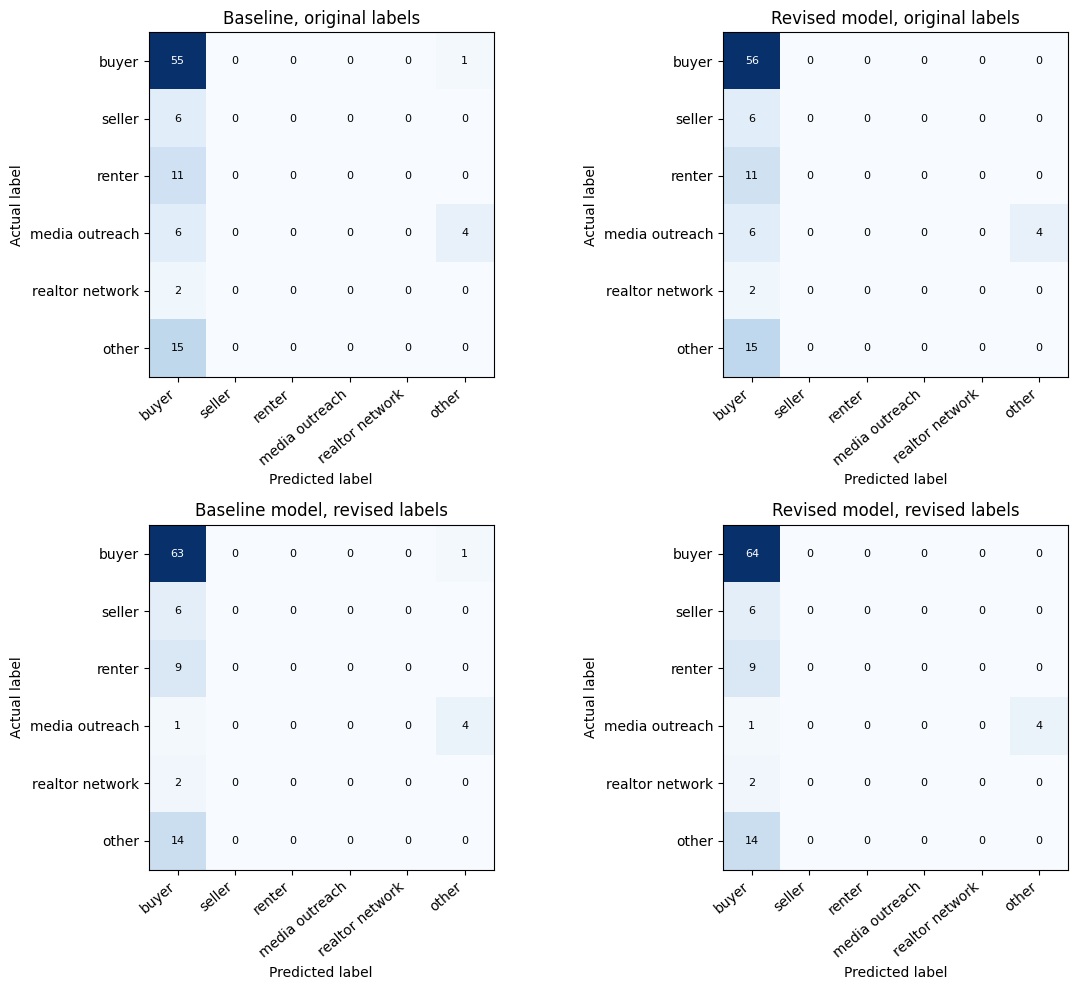

In [7]:
comparison_rows = []
for metric_name, column_name in (
    ("accuracy", "accuracy"),
    ("macro precision", "macro_precision"),
    ("macro recall", "macro_recall"),
    ("macro f1", "macro_f1"),
    ("macro specificity", "macro_specificity"),
    ("macro auc", "macro_auc"),
):
    comparison_row = {"metric": metric_name}
    for experiment_name, experiment in experiments.items():
        comparison_row[experiment_name] = experiment["repeat_summary"][column_name].mean()
    comparison_rows.append(comparison_row)
comparison = pd.DataFrame(comparison_rows).set_index("metric")
print("Mean of the 10 repeat scores.")
display(comparison.round(3))

baseline_accuracy = comparison.loc["accuracy", "Baseline, original labels"]
retrained_accuracy = comparison.loc["accuracy", "Revised model, original labels"]
relabeled_accuracy = comparison.loc["accuracy", "Baseline model, revised labels"]
both_accuracy = comparison.loc["accuracy", "Revised model, revised labels"]
print(
    f"Retraining, with the original test labels, changes accuracy by {retrained_accuracy - baseline_accuracy:+.3f}."
)
print(
    f"Rescoring the Assignment 9 model on the revised test labels changes accuracy by {relabeled_accuracy - baseline_accuracy:+.3f}."
)
print(
    f"The retrained model on the revised test labels differs from Assignment 9 by {both_accuracy - baseline_accuracy:+.3f}."
)

buyer_rows = []
for experiment_name, experiment in experiments.items():
    class_summary = experiment["class_summary"]
    buyer = class_summary.loc[class_summary["class_name"] == "buyer"].iloc[0]
    buyer_rows.append({
        "experiment": experiment_name,
        "precision": buyer["precision_mean"],
        "recall": buyer["recall_mean"],
        "f1": buyer["f1_mean"],
        "specificity": buyer["specificity_mean"],
        "auc": buyer["auc_mean"],
    })
print("Buyer is the only class the model predicts often enough to have precision and F1.")
display(pd.DataFrame(buyer_rows).set_index("experiment").round(3))

print("Pooled confusion matrices. Rows are the reference label and columns are the prediction.")
for experiment_name, experiment in experiments.items():
    print(experiment_name)
    display(confusion_frame(experiment))

figure, axes = plt.subplots(2, 2, figsize=(12, 10))
for axis, (experiment_name, experiment) in zip(axes.ravel(), experiments.items()):
    image = axis.imshow(experiment["confusion"], cmap="Blues")
    axis.set_xticks(range(len(CLASS_NAMES)))
    axis.set_yticks(range(len(CLASS_NAMES)))
    axis.set_xticklabels(CLASS_NAMES, rotation=40, ha="right")
    axis.set_yticklabels(CLASS_NAMES)
    axis.set_xlabel("Predicted label")
    axis.set_ylabel("Actual label")
    axis.set_title(experiment_name)
    darkest = experiment["confusion"].max() / 2 if experiment["confusion"].max() else 0
    for row_index in range(len(CLASS_NAMES)):
        for column_index in range(len(CLASS_NAMES)):
            count = int(experiment["confusion"][row_index, column_index])
            text_color = "white" if count > darkest else "black"
            axis.text(column_index, row_index, str(count), ha="center", va="center", color=text_color, fontsize=8)
figure.tight_layout()
plt.show()


## What the comparison shows

The next cell reads the held-out predictions. The three revised messages, the single prediction that retraining changes, and the relationship to alpha are reported from those tables.


In [8]:
baseline_predictions = experiments["Baseline, original labels"]["predictions"]
revised_predictions = experiments["Revised model, original labels"]["predictions"]
merged = baseline_predictions.merge(
    revised_predictions,
    on=["repeat", "item_id"],
    suffixes=("_baseline", "_revised"),
)
changed_predictions = merged.loc[
    merged["predicted_label_baseline"] != merged["predicted_label_revised"]
]
print(
    f"On the original test labels, retraining changes {len(changed_predictions)} "
    f"of {len(merged)} held-out predictions."
)
if len(changed_predictions):
    display(changed_predictions[[
        "repeat", "item_id", "actual_label_baseline", "predicted_label_baseline", "predicted_label_revised",
    ]])

changed_ids = changed_labels["item_id"].tolist()
focus = baseline_predictions.loc[baseline_predictions["item_id"].isin(changed_ids)]
print("Assignment 9 predictions for the three relabeled messages, on the repeats where each one is held out:")
display(
    focus.groupby(["item_id", "actual_label", "predicted_label"]).size().rename("test_appearances").reset_index()
)

f1_classes_baseline = experiments["Baseline, original labels"]["repeat_summary"]["f1_classes_counted"].mean()
f1_classes_revised = experiments["Revised model, original labels"]["repeat_summary"]["f1_classes_counted"].mean()
print(
    f"Macro F1 averages {f1_classes_baseline:.1f} classes per repeat for the baseline "
    f"and {f1_classes_revised:.1f} for the retrained model. "
    "A class the model never predicts is left out of that average, so macro F1 can rise "
    "when a zero F1 drops out."
)
print(
    f"Baseline alpha is {baseline_agreement['alpha']:.3f} and revised alpha is {revised_agreement['alpha']:.3f}. "
    "Minority-class recall stays 0 after retraining. The accuracy change on the original key is one prediction. "
    "The larger accuracy change appears when V16 and V22 are scored as buyer, which is the label both models already predict for those held-out rows. "
    "Reported accuracy can rise because the reference label moves onto the class the model already emits, while the six classes remain unseparated."
)
print(
    "This comparison edits 3 of the 30 Assignment 9 messages. "
    "The form-only messages, including extra realtor-network and media-outreach examples, are not in the training set. "
    "The results describe these splits. They do not estimate a model trained on the whole form."
)


On the original test labels, retraining changes 1 of 100 held-out predictions.


,repeat,item_id,actual_label_baseline,predicted_label_baseline,predicted_label_revised
85,9,V2,buyer,other,buyer


Assignment 9 predictions for the three relabeled messages, on the repeats where each one is held out:


,item_id,actual_label,predicted_label,test_appearances
0,V16,renter,buyer,2
1,V22,other,buyer,6
2,V27,media outreach,buyer,5


Macro F1 averages 1.4 classes per repeat for the baseline and 1.3 for the retrained model. A class the model never predicts is left out of that average, so macro F1 can rise when a zero F1 drops out.
Baseline alpha is 0.517 and revised alpha is 0.546. Minority-class recall stays 0 after retraining. The accuracy change on the original key is one prediction. The larger accuracy change appears when V16 and V22 are scored as buyer, which is the label both models already predict for those held-out rows. Reported accuracy can rise because the reference label moves onto the class the model already emits, while the six classes remain unseparated.
This comparison edits 3 of the 30 Assignment 9 messages. The form-only messages, including extra realtor-network and media-outreach examples, are not in the training set. The results describe these splits. They do not estimate a model trained on the whole form.


## Saved tables

The cell below writes the tables displayed above to `Module_10_assignment/outputs`, next to the label-change list. The notebook output is the submission record. The files make the same numbers easy to reopen.


In [9]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
excluded_rows = excluded_form.rename(columns={"item_id": "module_10_item_id", "final_label": "revised_label"}).copy()
excluded_rows.insert(0, "item_id", "")
excluded_rows["original_label"] = ""
excluded_rows["label_changed"] = False
excluded_rows["votes"] = ""
excluded_rows["note"] = "Not in the Assignment 9 set, so this form message was not added."
label_columns = ["item_id", "module_10_item_id", "original_label", "revised_label", "label_changed", "votes", "note"]
pd.concat([label_table, excluded_rows], ignore_index=True)[label_columns].to_csv(
    OUTPUT_DIR / "label_changes.csv", index=False
)
folder_names = {
    "Baseline, original labels": "baseline_on_original_labels",
    "Revised model, original labels": "revised_on_original_labels",
    "Baseline model, revised labels": "baseline_on_revised_labels",
    "Revised model, revised labels": "revised_on_revised_labels",
}
for experiment_name, folder_name in folder_names.items():
    folder = OUTPUT_DIR / folder_name
    folder.mkdir(parents=True, exist_ok=True)
    experiment = experiments[experiment_name]
    experiment["class_summary"].to_csv(folder / "class_metrics_summary.csv", index=False)
    experiment["repeat_summary"].to_csv(folder / "repeat_summary.csv", index=False)
    experiment["predictions"].to_csv(folder / "test_predictions.csv", index=False)
    confusion_frame(experiment).to_csv(folder / "confusion_matrix_sum.csv")
comparison.round(6).to_csv(OUTPUT_DIR / "comparison_metrics.csv")
print(f"Wrote label changes, comparison metrics, and four experiment folders to {OUTPUT_DIR}.")


Wrote label changes, comparison metrics, and four experiment folders to E:\Human-in-the-loop-AI\Module_10_assignment\outputs.
